# Hurricane Charley (2004): USA losses for three versions of the hazard
Locally computed wind fields with a 1 h and a 10 min track time step, plus the pre-computed (older wind model) hazard from the Data API.

In [1]:
import copy
import numpy as np
from climada.hazard import TCTracks, TropCyclone, Centroids
from climada.entity import Exposures, ImpactFuncSet, ImpfTropCyclone
from climada.engine import ImpactCalc
from climada.util.api_client import Client

## Track (IBTrACS ID of Charley: 2004223N11301)

2026-10-30 16:34:56,346 - climada.hazard.tc_tracks - WARNING - The cached IBTrACS data set dates from 2026-03-31 17:46:48 (older than 180 days). Very likely, a more recent version is available. Consider manually removing the file /Users/chrisfairless/Projects/climada/climada_python/data/IBTrACS.ALL.v04r01.nc and re-running this function, which will download the most recent version of the IBTrACS data set from the official URL.
2026-10-30 16:35:00,201 - climada.hazard.tc_tracks - INFO - Progress: 100%


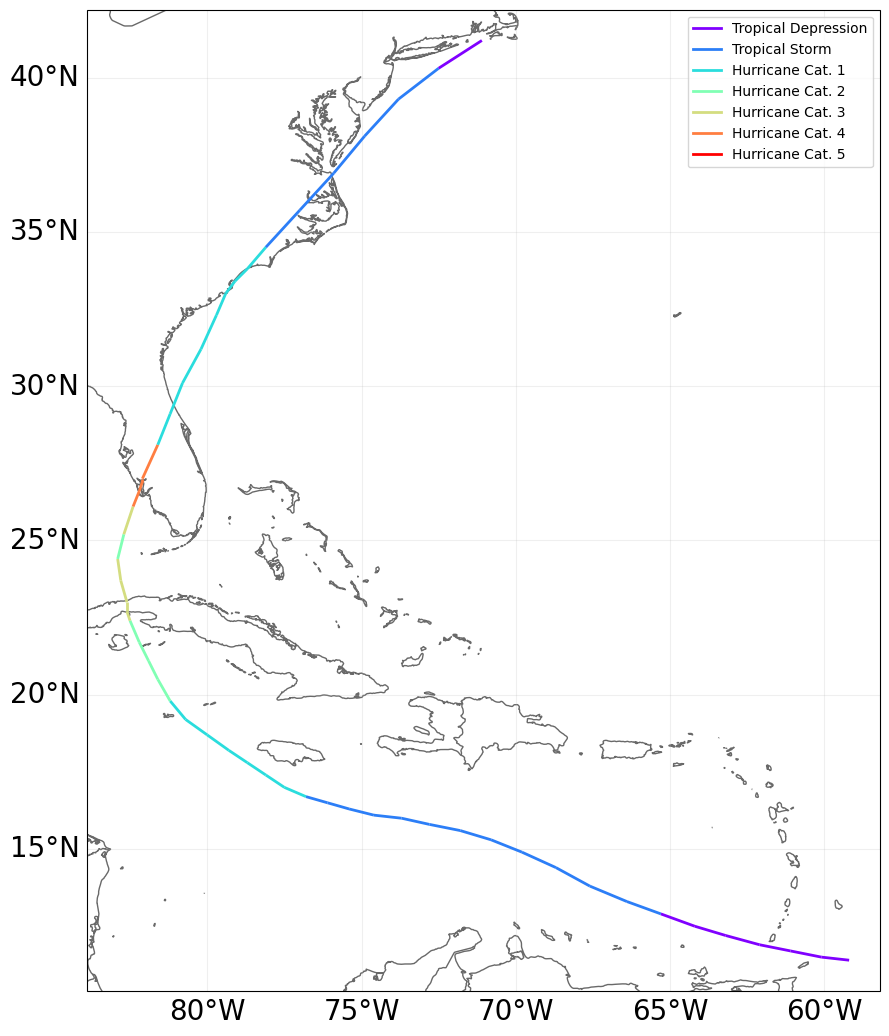

In [2]:
tracks_raw = TCTracks.from_ibtracs_netcdf(storm_id='2004223N11301')
tracks_raw.plot();

## Exposures (LitPop via data API) and impact function (Emanuel USA)

In [3]:
exp = Client().get_litpop(country='USA')
exp.data['impf_TC'] = 1
impf_set = ImpactFuncSet([ImpfTropCyclone.from_emanuel_usa()])
print(exp.data.shape, exp.data.value.sum())

2026-10-30 16:35:04,082 - climada.entity.exposures.base - INFO - Reading /Users/chrisfairless/Projects/climada/climada_python/data/exposures/litpop/LitPop_150arcsec_USA/v3/LitPop_150arcsec_USA.hdf5
(643099, 5) 65384554304412.63


## Hazard from the Data API (older wind model) and shared centroids/exposure
The API hazard is trimmed to the region of interest (lon -83 to -75, lat 24 to 37). Its centroids are used for all three versions, and the exposure is cut to the same region and assigned to them once.

In [4]:
# extent = (lon_min, lon_max, lat_min, lat_max)
LON_MIN, LON_MAX, LAT_MIN, LAT_MAX = -83, -75, 24, 37

haz_api = Client().get_hazard(
    'tropical_cyclone',
    properties={'event_type': 'observed', 'country_iso3alpha': 'USA', 'climate_scenario': 'None'},
)
haz_api = haz_api.select(event_names=['2004223N11301'], extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
cent = haz_api.centroids

d = exp.data
sel = d[(d.value > 0) & d.geometry.y.between(LAT_MIN, LAT_MAX) & d.geometry.x.between(LON_MIN, LON_MAX)]
exp_sel = Exposures(sel.copy(), crs=exp.crs, value_unit=exp.value_unit)
print(cent.size, 'centroids;', len(sel), 'exposure points')

2026-10-30 16:35:16,502 - climada.hazard.io - INFO - Reading /Users/chrisfairless/Projects/climada/climada_python/data/hazard/tropical_cyclone/tropical_cyclone_0synth_tracks_150arcsec_historical_USA_1980_2020/v2/tropical_cyclone_0synth_tracks_150arcsec_historical_USA_1980_2020.hdf5
22139 centroids; 21556 exposure points


## Impacts for each version

In [5]:
results = {}
imp = ImpactCalc(exp_sel, impf_set, haz_api).impact(assign_centroids=True, save_mat=False)
results['Data API'] = (haz_api, imp)
print(f'Data API: max wind={haz_api.intensity.max():.1f} m/s, total loss={imp.at_event[0]:,.0f} USD')

for label, dt_h in [('1 h', 1), ('10 min', 1/6)]:
    tr = copy.deepcopy(tracks_raw)
    tr.equal_timestep(time_step_h=dt_h)
    haz = TropCyclone.from_tracks(tr, centroids=cent)
    imp = ImpactCalc(exp_sel, impf_set, haz).impact(assign_centroids=True, save_mat=False)
    results[label] = (haz, imp)
    print(f'{label}: n track points={tr.data[0].time.size}, max wind={haz.intensity.max():.1f} m/s, total loss={imp.at_event[0]:,.0f} USD')

2026-10-30 16:35:18,177 - climada.entity.exposures.base - INFO - Matching 21556 exposures with 22139 centroids.
2026-10-30 16:35:18,256 - climada.util.coordinates - INFO - No exact centroid match found. Reprojecting coordinates to nearest neighbor closer than the threshold = 0.08333333333331439 degree
2026-10-30 16:35:18,282 - climada.util.coordinates - WARNING - Distance to closest centroid is greater than 0.083333 degree for 3 coordinates.
2026-10-30 16:35:18,290 - climada.engine.impact_calc - INFO - Calculating impact for 64659 assets (>0) and 1 events.
Data API: max wind=69.0 m/s, total loss=236,732,475,896 USD
2026-10-30 16:35:18,308 - climada.hazard.tc_tracks - INFO - Interpolating 1 tracks to 1h time steps.
2026-10-30 16:35:18,380 - climada.hazard.trop_cyclone.trop_cyclone - INFO - Mapping 1 tracks to 22139 coastal centroids.


<string>:7: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.


2026-10-30 16:35:19,227 - climada.hazard.trop_cyclone.trop_cyclone - INFO - Progress: 100%
2026-10-30 16:35:19,761 - climada.entity.exposures.base - INFO - Existing centroids will be overwritten for TC
2026-10-30 16:35:19,762 - climada.entity.exposures.base - INFO - Matching 21556 exposures with 22139 centroids.
2026-10-30 16:35:19,805 - climada.util.coordinates - INFO - No exact centroid match found. Reprojecting coordinates to nearest neighbor closer than the threshold = 0.08333333333331439 degree
2026-10-30 16:35:19,838 - climada.util.coordinates - WARNING - Distance to closest centroid is greater than 0.083333 degree for 3 coordinates.
2026-10-30 16:35:19,842 - climada.engine.impact_calc - INFO - Calculating impact for 64659 assets (>0) and 1 events.
1 h: n track points=145, max wind=59.1 m/s, total loss=15,566,035,118 USD
2026-10-30 16:35:19,859 - climada.hazard.tc_tracks - INFO - Interpolating 1 tracks to 0.16666666666666666h time steps.
2026-10-30 16:35:19,917 - climada.hazard.t

<string>:7: FutureWarning: 'T' is deprecated and will be removed in a future version. Please use 'min' instead of 'T'.


2026-10-30 16:35:25,561 - climada.hazard.trop_cyclone.trop_cyclone - INFO - Progress: 100%
2026-10-30 16:35:26,166 - climada.entity.exposures.base - INFO - Existing centroids will be overwritten for TC
2026-10-30 16:35:26,166 - climada.entity.exposures.base - INFO - Matching 21556 exposures with 22139 centroids.
2026-10-30 16:35:26,209 - climada.util.coordinates - INFO - No exact centroid match found. Reprojecting coordinates to nearest neighbor closer than the threshold = 0.08333333333331439 degree
2026-10-30 16:35:26,230 - climada.util.coordinates - WARNING - Distance to closest centroid is greater than 0.083333 degree for 3 coordinates.
2026-10-30 16:35:26,234 - climada.engine.impact_calc - INFO - Calculating impact for 64659 assets (>0) and 1 events.
10 min: n track points=865, max wind=62.6 m/s, total loss=25,791,778,960 USD


## Comparison

Data API: 236,732,475,896 USD (+1420.8% vs 1 h)
1 h     : 15,566,035,118 USD (+0.0% vs 1 h)
10 min  : 25,791,778,960 USD (+65.7% vs 1 h)


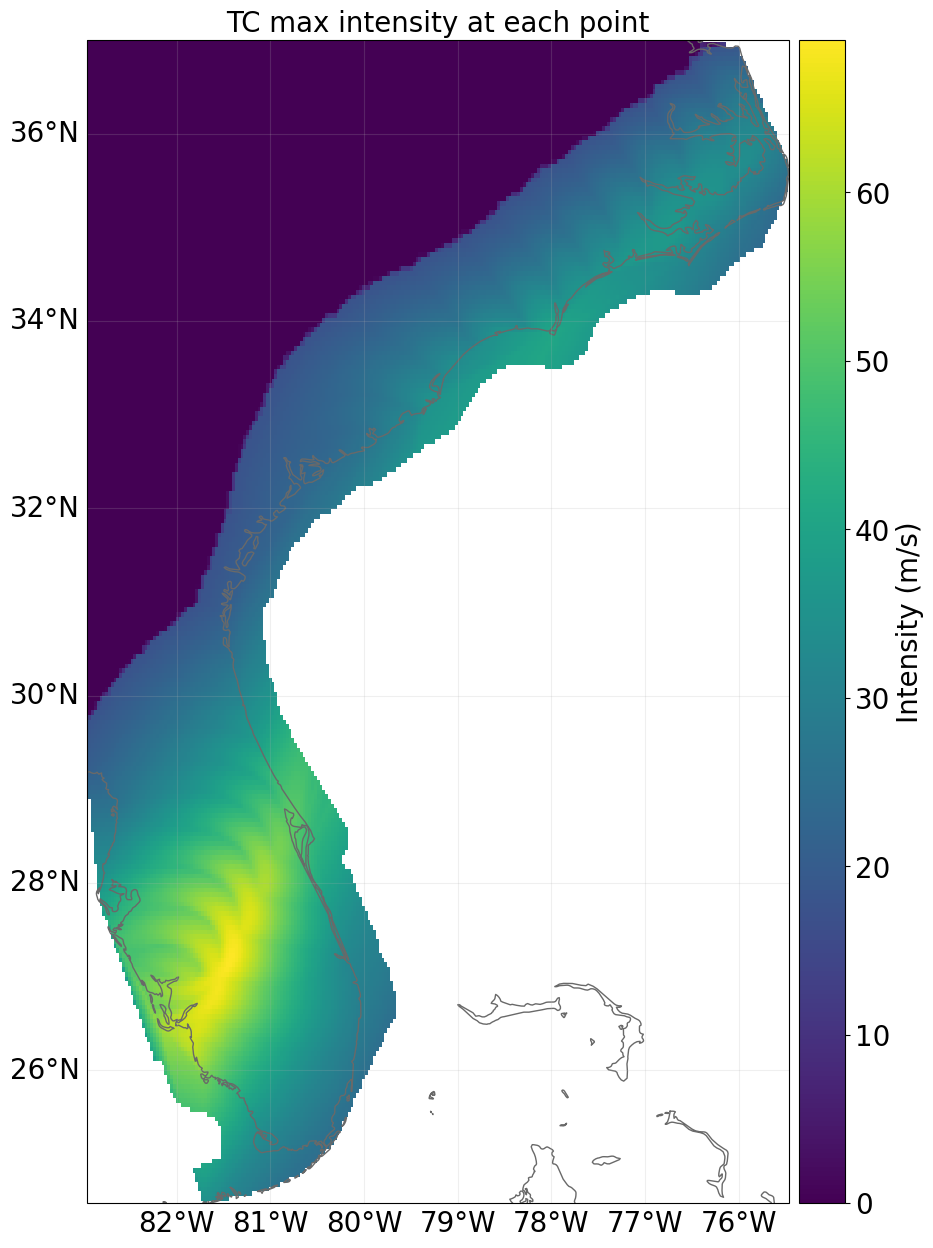

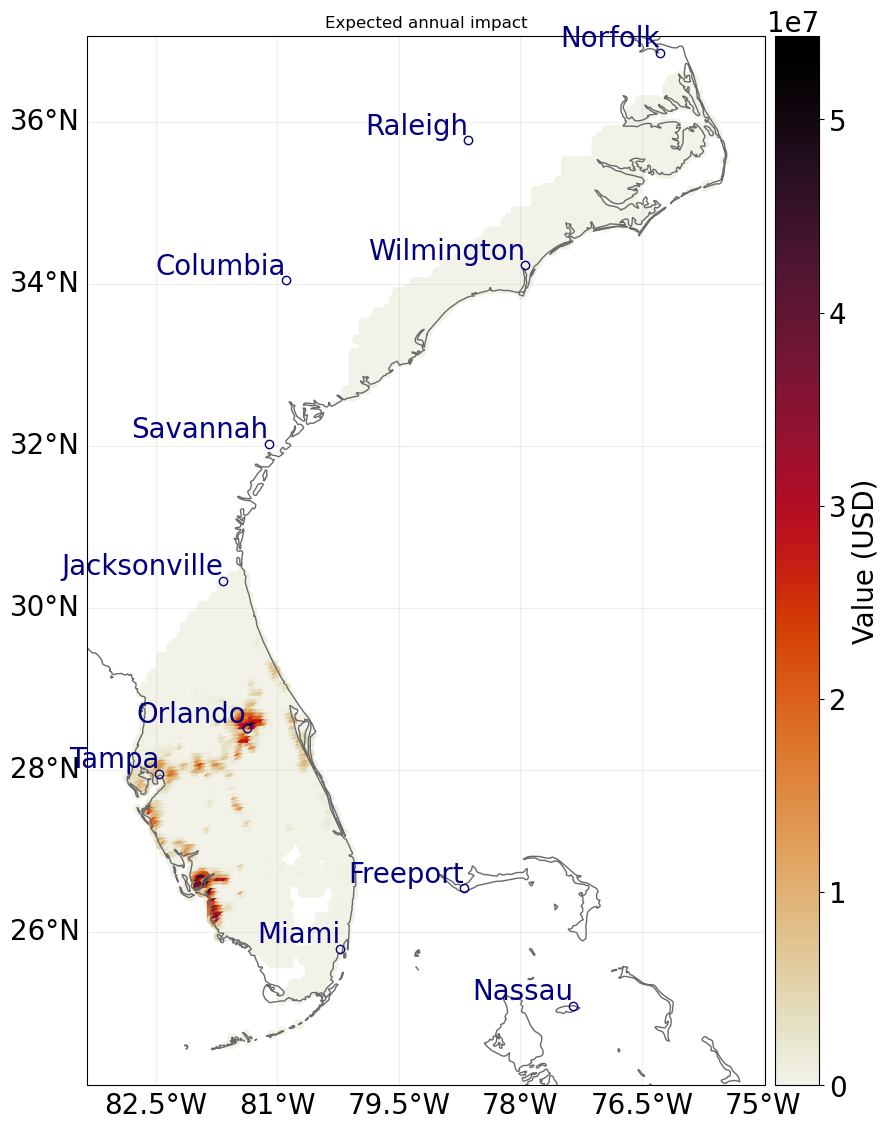

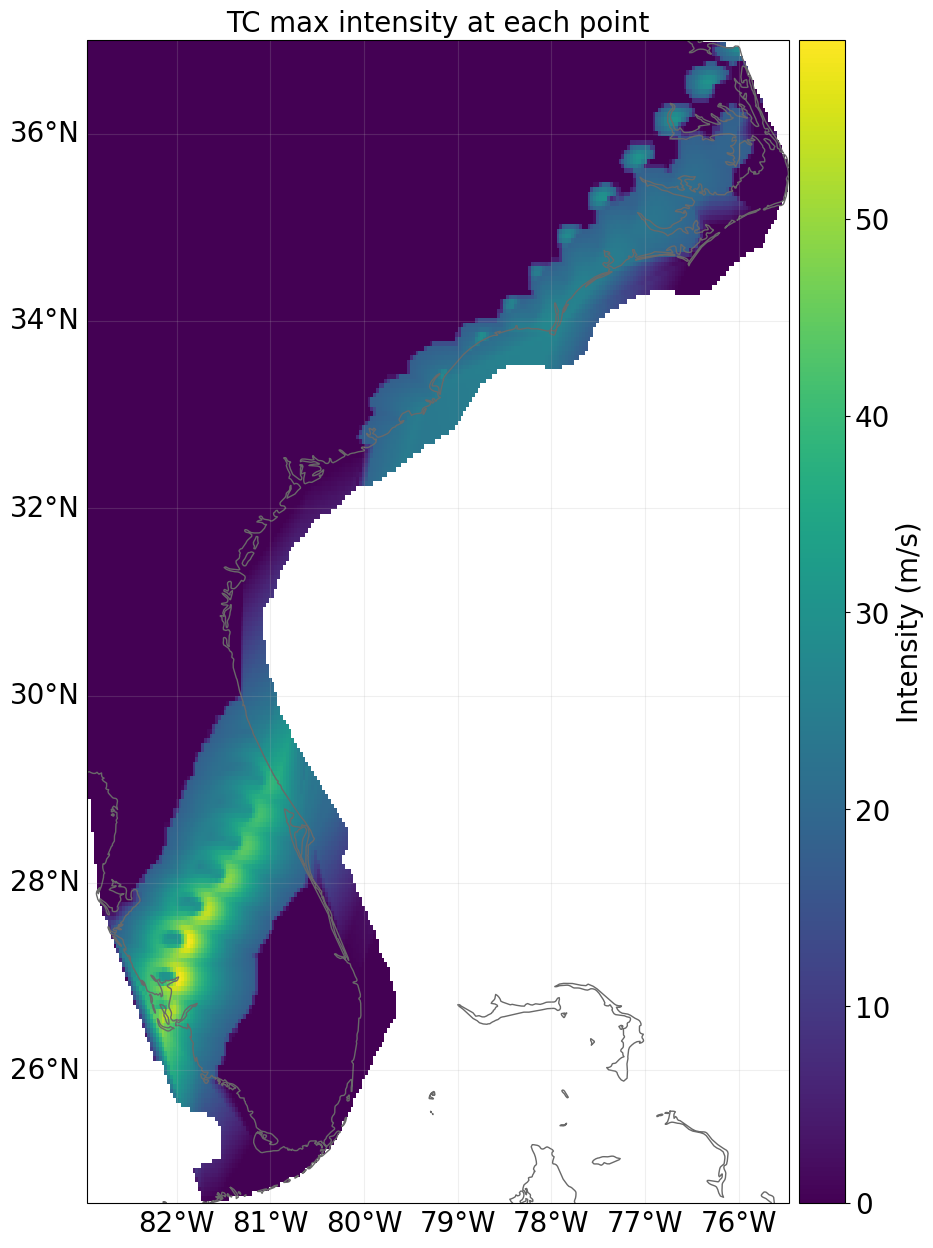

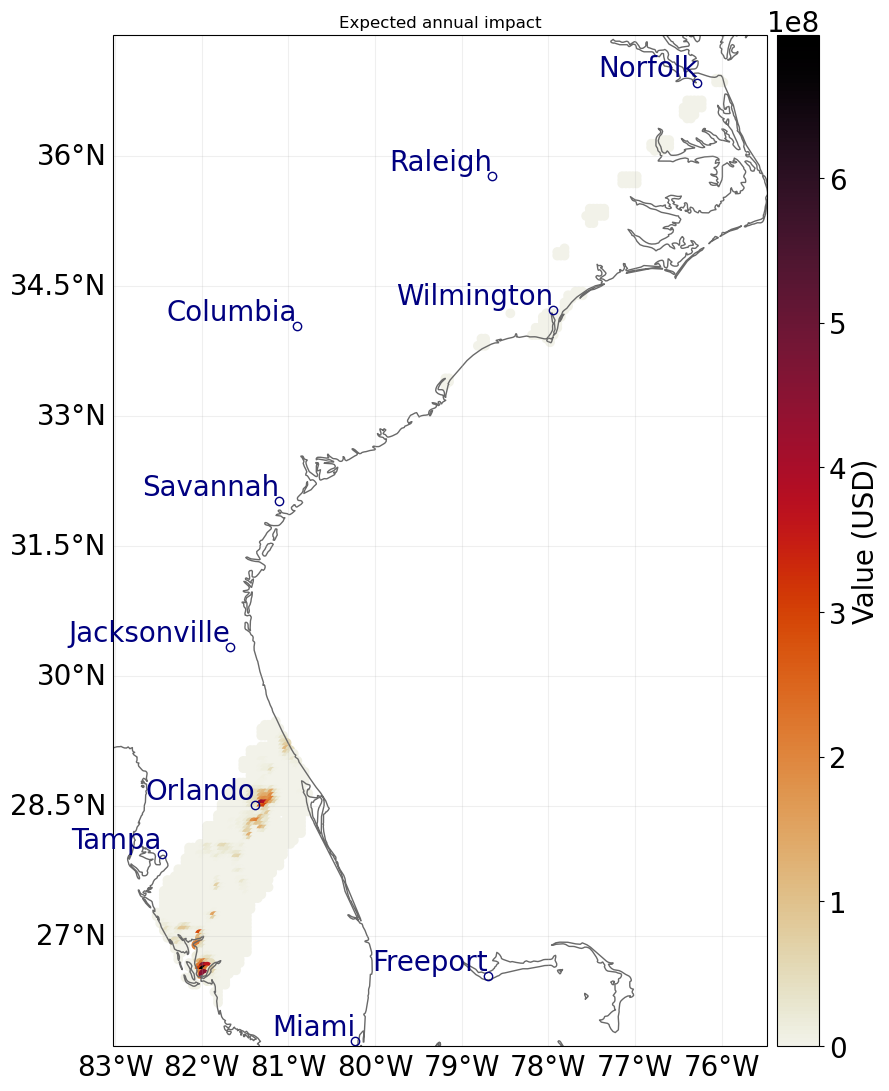

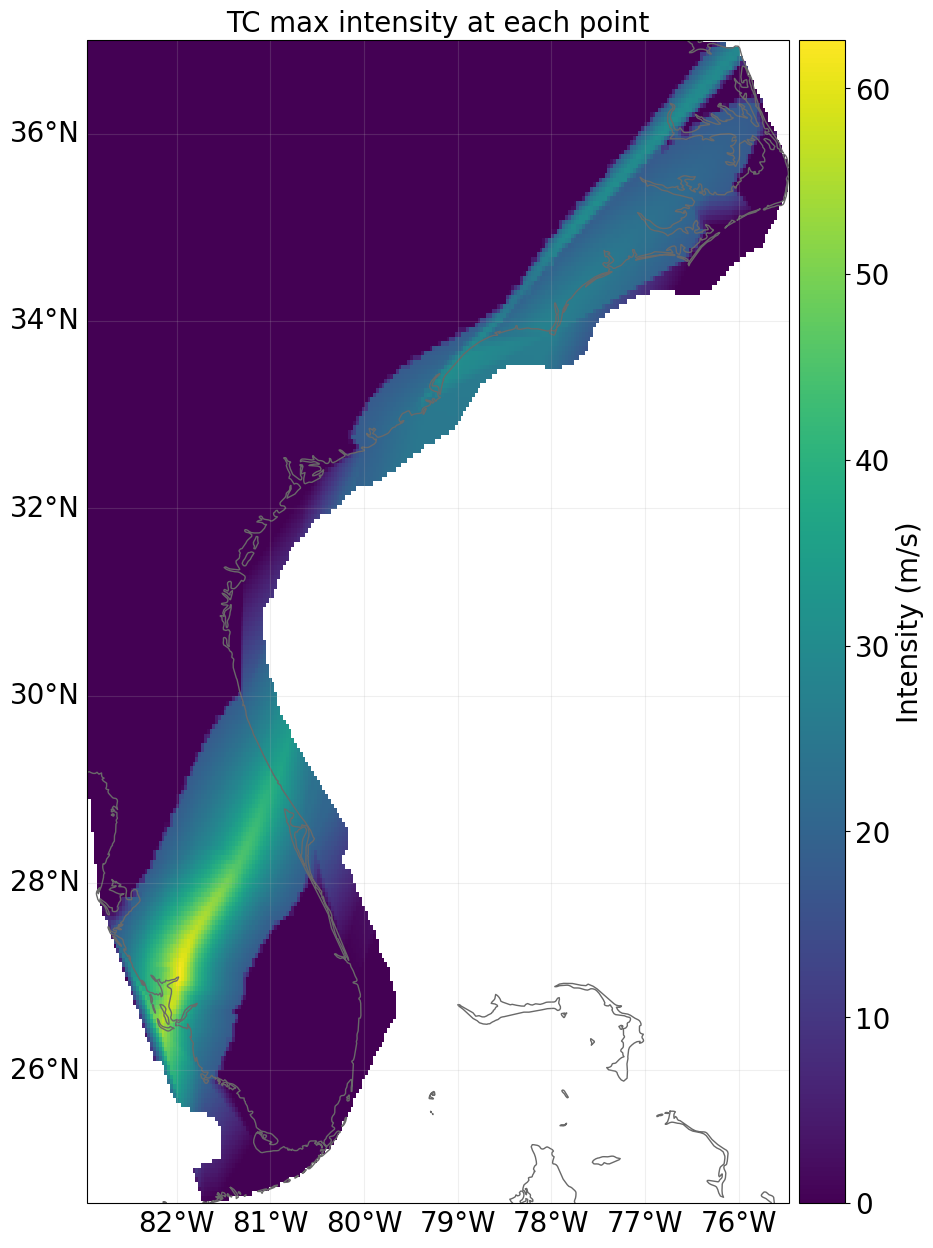

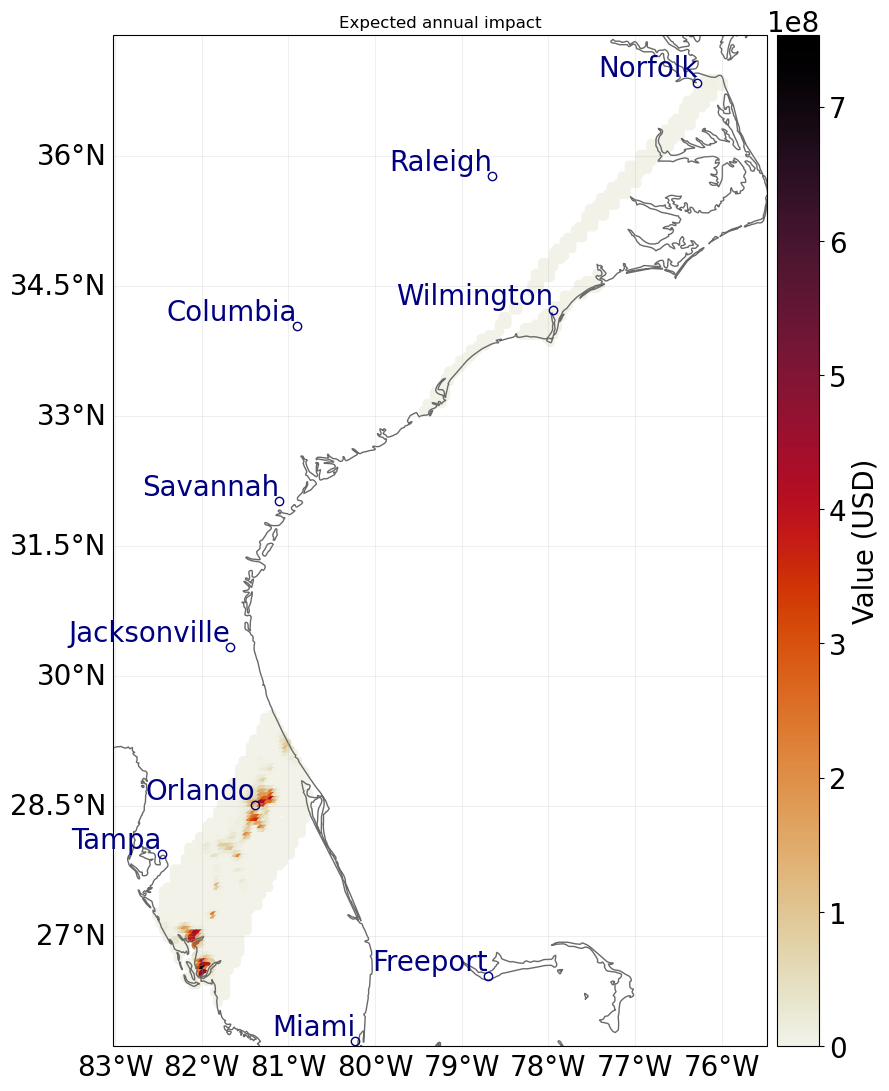

In [6]:
base = results['1 h'][1].at_event[0]
for label, (haz, imp) in results.items():
    l = imp.at_event[0]
    print(f'{label:8s}: {l:,.0f} USD ({100*(l-base)/base:+.1f}% vs 1 h)')
for label, (haz, imp) in results.items():
    haz.plot_intensity(event=0)
    imp.plot_scatter_eai_exposure(ignore_zero=True, buffer=0.5)